<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Outliers**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform exploratory data analysis or EDA. 
You will explore the distribution of key variables and focus on identifying outliers in this lab.


## Objectives


In this lab, you will perform the following:


-  Analyze the distribution of key variables in the dataset.

-  Identify and remove outliers using statistical methods.

-  Perform relevant statistical and correlation analysis.


#### Install and import the required libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

<h3>Step 1: Load and Explore the Dataset</h3>


Load the dataset into a DataFrame and examine the structure of the data.


In [2]:
file_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

#Create the dataframe
df = pd.read_csv(file_url)

#Display the top 10 records
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


<h3>Step 2: Plot the Distribution of Industry</h3>


Explore how respondents are distributed across different industries.

- Plot a bar chart to visualize the distribution of respondents by industry.

- Highlight any notable trends.


,Respondents
Industry,
Software Development,11918
Other:,3077
Fintech,1641
"Internet, Telecomm or Information Services",1629
Banking/Financial Services,1371
Healthcare,1277
Manufacturing,1265
Retail and Consumer Services,1264
Government,962


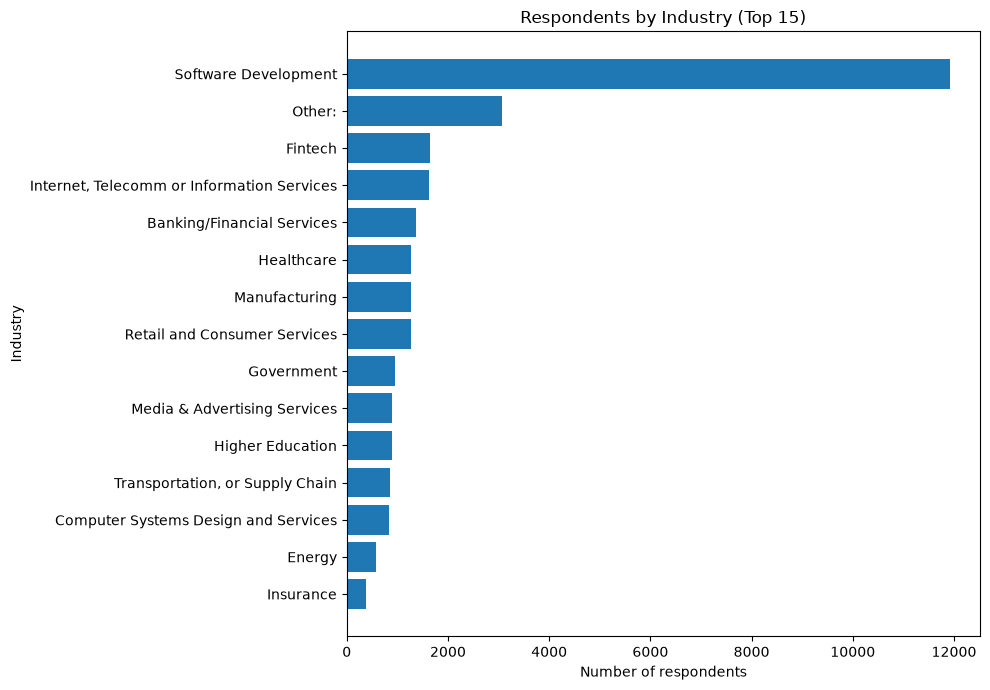

Most common industry: Software Development (11918 respondents, 41.3% of valid responses)


In [3]:
import matplotlib.pyplot as plt

# Count non-missing industry responses
industry_counts = (
    df["Industry"]
    .dropna()
    .astype(str)
    .str.strip()
)
industry_counts = industry_counts[industry_counts != ""].value_counts()

display(industry_counts.rename("Respondents").to_frame())

# Plot the 15 most common industries
top_industries = industry_counts.head(15).sort_values()

plt.figure(figsize=(10, 7))
plt.barh(top_industries.index, top_industries.values)
plt.title("Respondents by Industry (Top 15)")
plt.xlabel("Number of respondents")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

# Highlight the most common industry
top_industry = industry_counts.index[0]
top_count = industry_counts.iloc[0]
top_percent = top_count / industry_counts.sum() * 100

print(
    f"Most common industry: {top_industry} "
    f"({top_count} respondents, {top_percent:.1f}% of valid responses)"
)

<h3>Step 3: Identify High Compensation Outliers</h3>


Identify respondents with extremely high yearly compensation.

- Calculate basic statistics (mean, median, and standard deviation) for `ConvertedCompYearly`.

- Identify compensation values exceeding a defined threshold (e.g., 3 standard deviations above the mean).


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df["ConvertedCompYearly"] = pd.to_numeric(
    df["ConvertedCompYearly"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

compensation = df["ConvertedCompYearly"].dropna()

print("Mean:", compensation.mean())
print("Median:", compensation.median())
print("Standard deviation:", compensation.std())

high_threshold = compensation.mean() + 3 * compensation.std()
high_compensation = df[df["ConvertedCompYearly"] > high_threshold]

print(f"\nHigh-compensation threshold: {high_threshold:,.2f}")
print("Rows above threshold:", len(high_compensation))

display(
    high_compensation
    .sort_values("ConvertedCompYearly", ascending=False)
    .head(10)
)

Mean: 86155.28726264134
Median: 65000.0
Standard deviation: 186756.97308629754

High-compensation threshold: 646,426.21
Rows above threshold: 89


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
15837,15838,I am a developer by profession,25-34 years old,"Independent contractor, freelancer, or self-em...",In-person,Apples,Hobby;Contribute to open-source projects;Boots...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,16256603.0,NaN
12723,12724,I am a developer by profession,25-34 years old,"Employed, full-time;Independent contractor, fr...","Hybrid (some remote, some in-person)",Apples,Contribute to open-source projects;Professiona...,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",Books / Physical media;On the job training;Oth...,Blogs;Stack Overflow;Coding sessions (live or ...,...,100.0,100.0,100.0,100.0,100.0,100.0,Appropriate in length,Neither easy nor difficult,13818022.0,10.0
28379,28380,I am a developer by profession,18-24 years old,"Employed, full-time","Hybrid (some remote, some in-person)",Apples,Contribute to open-source projects,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",Books / Physical media;On the job training;Oth...,Technical documentation;Blogs;Books;Written Tu...,...,100.0,100.0,100.0,100.0,100.0,100.0,Appropriate in length,Neither easy nor difficult,9000000.0,10.0
17593,17594,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Professional development or self-paced l...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;On the job training;Oth...,Technical documentation;Books;Written Tutorial...,...,75.0,40.0,30.0,40.0,30.0,70.0,Appropriate in length,Easy,6340564.0,6.0
17672,17673,I am a developer by profession,25-34 years old,"Employed, full-time",Remote,Apples,Hobby;School or academic work,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Stack Overflow;V...,...,25.0,35.0,20.0,10.0,0.0,0.0,Too long,Neither easy nor difficult,4936778.0,7.0
19267,19268,I am a developer by profession,25-34 years old,"Employed, full-time",In-person,Apples,Hobby;Professional development or self-paced l...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Blogs;Books;Written Tutorials;Stack Overflow;C...,...,20.0,30.0,30.0,0.0,0.0,0.0,Appropriate in length,Easy,3367716.0,7.0
23694,23695,I am a developer by profession,18-24 years old,"Employed, full-time;Independent contractor, fr...",Remote,Apples,Freelance/contract work,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",On the job training;Other online resources (e....,Technical documentation;Written Tutorials;Writ...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Difficult,2584118.0,NaN
33720,33721,I am a developer by profession,25-34 years old,"Independent contractor, freelancer, or self-em...",Remote,Apples,Contribute to open-source projects;Freelance/c...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,2237846.0,NaN
34523,34524,I am a developer by profession,18-24 years old,"Employed, full-time",In-person,Apples,Hobby;Professional development or self-paced l...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",On the job training;Online Courses or Certific...,NaN,...,100.0,100.0,100.0,100.0,100.0,100.0,Too long,Difficult,2153432.0,10.0
13763,13764,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Contribute to open-source projects;Freelance/c...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Stack Overflow;AI,...,0.0,0.0,0.0,0.0,0.0,0.0,Too long,Difficult,2048046.0,10.0


<h3>Step 4: Detect Outliers in Compensation</h3>


Identify outliers in the `ConvertedCompYearly` column using the IQR method.

- Calculate the Interquartile Range (IQR).

- Determine the upper and lower bounds for outliers.

- Count and visualize outliers using a box plot.


Q1: 32712.0
Q3: 107971.5
IQR: 75259.5
Lower bound: -80177.25
Upper bound: 220860.75
Number of outliers: 978


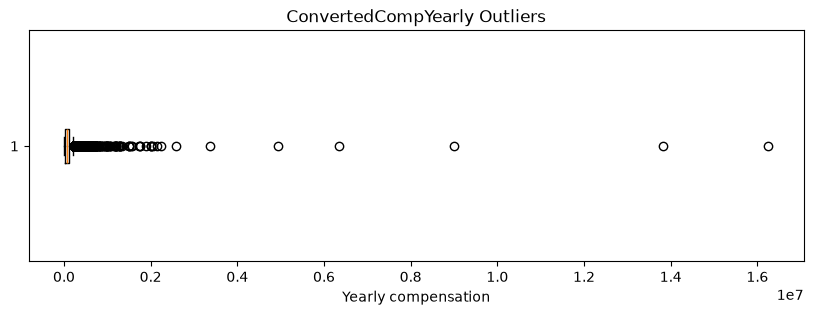

In [6]:
q1 = compensation.quantile(0.25)
q3 = compensation.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (df["ConvertedCompYearly"] < lower_bound) |
    (df["ConvertedCompYearly"] > upper_bound)
)

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", outlier_mask.sum())

plt.figure(figsize=(10, 3))
plt.boxplot(compensation, orientation="horizontal")
plt.xlabel("Yearly compensation")
plt.title("ConvertedCompYearly Outliers")
plt.show()

<h3>Step 5: Remove Outliers and Create a New DataFrame</h3>


Remove outliers from the dataset.

- Create a new DataFrame excluding rows with outliers in `ConvertedCompYearly`.
- Validate the size of the new DataFrame.


In [7]:
df_no_outliers = df.loc[~outlier_mask].copy()

print("Original rows:", len(df))
print("Rows after removing outliers:", len(df_no_outliers))
print("Rows removed:", len(df) - len(df_no_outliers))

# Confirm no remaining compensation values fall outside the IQR bounds
remaining = df_no_outliers["ConvertedCompYearly"].dropna()
print(
    "Remaining IQR outliers:",
    ((remaining < lower_bound) | (remaining > upper_bound)).sum()
)

Original rows: 65437
Rows after removing outliers: 22457
Rows removed: 42980
Remaining IQR outliers: 0


<h3>Step 6: Correlation Analysis</h3>


Analyze the correlation between `Age` (transformed) and other numerical columns.

- Map the `Age` column to approximate numeric values.

- Compute correlations between `Age` and other numeric variables.

- Visualize the correlation matrix.


Unmapped age categories: <ArrowStringArray>
['Prefer not to say']
Length: 1, dtype: str


,Correlation with Age
WorkExp,0.852538
ConvertedCompYearly,0.120809
JobSatPoints_10,-0.114106
JobSatPoints_11,-0.107043
JobSatPoints_5,-0.101414
JobSatPoints_7,-0.082166
JobSatPoints_9,-0.081523
JobSatPoints_4,-0.075838
JobSat,0.069917
JobSatPoints_6,-0.050517


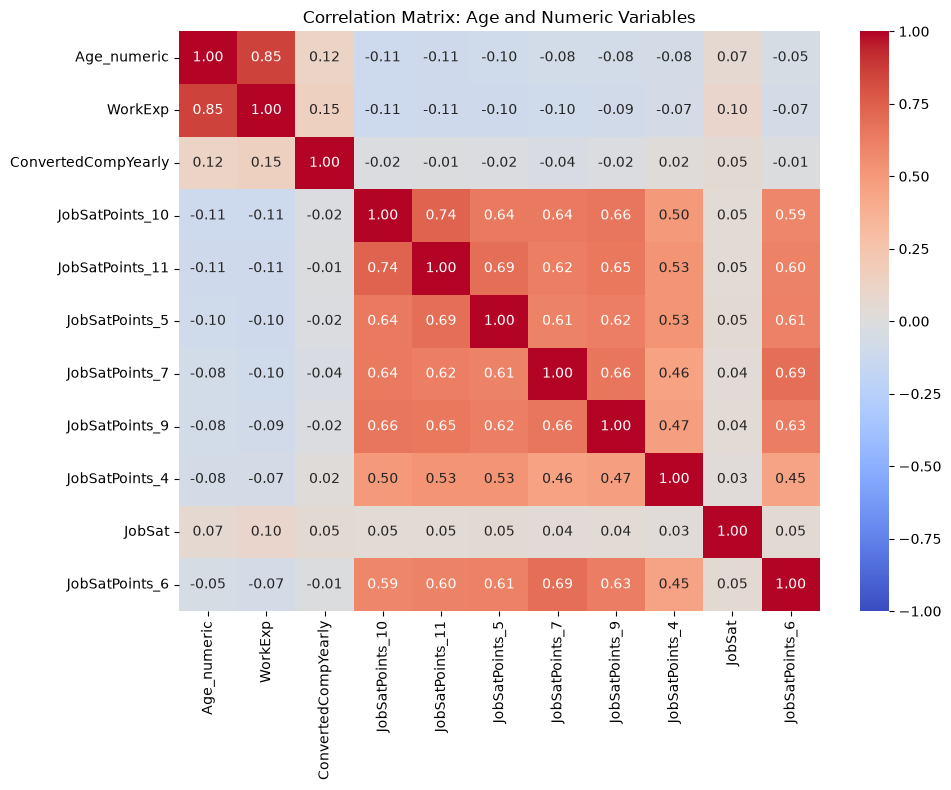

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 29,
    "35-44 years old": 39,
    "45-54 years old": 49,
    "55-64 years old": 59,
    "65 years or older": 70
}

df["Age_numeric"] = df["Age"].map(age_mapping)

# Show any age categories that were not matched by the mapping
unmapped_ages = df.loc[df["Age_numeric"].isna(), "Age"].dropna().unique()
print("Unmapped age categories:", unmapped_ages)

# Select numeric columns and exclude identifiers
numeric_data = df.select_dtypes(include="number").drop(
    columns=["ResponseId", "Age_numeric"],
    errors="ignore"
).copy()

numeric_data["Age_numeric"] = df["Age_numeric"]

# Exclude columns without enough values or with no variation
numeric_data = numeric_data.loc[:, numeric_data.notna().sum() > 1]
numeric_data = numeric_data.loc[:, numeric_data.nunique(dropna=True) > 1]

# Correlations between age and the other numeric columns
correlations = numeric_data.corr()["Age_numeric"].drop("Age_numeric").dropna()
correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

display(correlations.to_frame("Correlation with Age"))

# Heatmap: Age plus the 10 variables most correlated with age
top_columns = correlations.head(10).index.tolist()
columns_to_plot = ["Age_numeric"] + top_columns
correlation_matrix = numeric_data[columns_to_plot].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Correlation Matrix: Age and Numeric Variables")
plt.tight_layout()
plt.show()

<h3> Summary </h3>


In this lab, you developed essential skills in **Exploratory Data Analysis (EDA)** with a focus on outlier detection and removal. Specifically, you:


- Loaded and explored the dataset to understand its structure.

- Analyzed the distribution of respondents across industries.

- Identified and removed high compensation outliers using statistical thresholds and the Interquartile Range (IQR) method.

- Performed correlation analysis, including transforming the `Age` column into numeric values for better analysis.


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-1|1.1|Madhusudan Moole|Reviewed and updated lab|                                                                                    
|2024-09-29|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
